In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# 1. Load real tabular data: Wine dataset (13 features)
wine = load_wine()
X = wine.data          # shape (n_samples, 13)
y = wine.target        # 3 classes of wine
feature_names = wine.feature_names
n_samples, n_features = X.shape
print(f"Wine data shape: {X.shape}")   # (178, 13)




Wine data shape: (178, 13)


In [2]:
feature_names

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

Explained variance ratio (first 5 components):
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294]


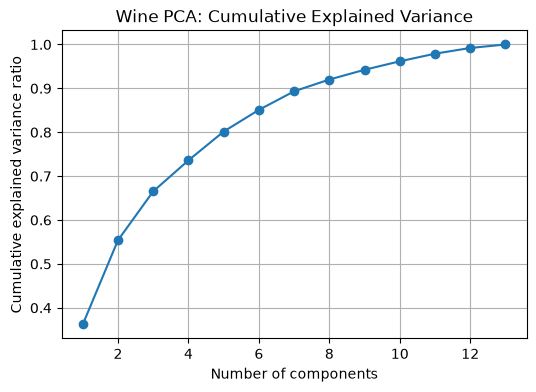

In [3]:
# 2. Standardize features (important for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Fit PCA with all components
pca_full = PCA(n_components=n_features)
X_scores = pca_full.fit_transform(X_scaled)        # Z = X W
X_recon_scaled = pca_full.inverse_transform(X_scores)
X_recon_full = scaler.inverse_transform(X_recon_scaled)

print("Explained variance ratio (first 5 components):")
print(pca_full.explained_variance_ratio_[:5])

# 4. Cumulative explained variance
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

plt.figure(figsize=(6, 4))
plt.plot(range(1, n_features + 1), cumulative_explained_variance, marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance ratio")
plt.title("Wine PCA: Cumulative Explained Variance")
plt.grid(True)
plt.show()


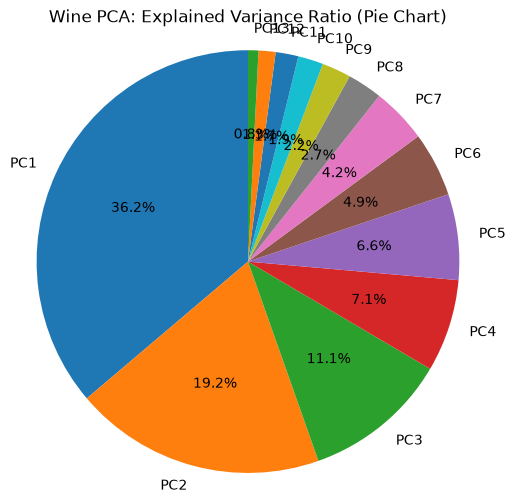

In [4]:
top_k = 13
ratios_top = explained_variance_ratio[:top_k]
ratios_rest = explained_variance_ratio[top_k:].sum()

labels = [f"PC{i+1}" for i in range(top_k)]
sizes = list(ratios_top)

# Group all remaining components into "Others"
if ratios_rest > 0:
    labels.append("Others")
    sizes.append(ratios_rest)

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",   # show percentages
    startangle=90        # rotate so first slice starts at the top
)
plt.title("Wine PCA: Explained Variance Ratio (Pie Chart)")
plt.axis("equal")        # make it a perfect circle
plt.show()

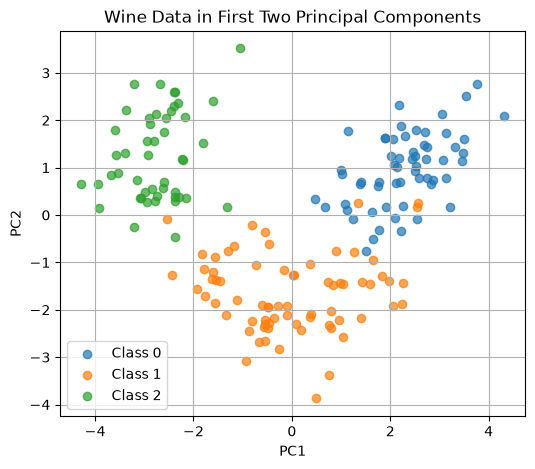

In [5]:

pca_2 = PCA(n_components=2)
Z_2 = pca_2.fit_transform(X_scaled)

plt.figure(figsize=(6, 5))
for label, color in zip(np.unique(y), ["tab:blue", "tab:orange", "tab:green"]):
    plt.scatter(
        Z_2[y == label, 0],
        Z_2[y == label, 1],
        label=f"Class {label}",
        alpha=0.7,
    )
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Wine Data in First Two Principal Components")
plt.legend()
plt.grid(True)
plt.show()

# PCA of the S&P 500 and Fama-French Factors

This section treats weekly stock returns as observations-by-assets and extracts three common return components. Each stock is standardized before PCA so that a highly volatile stock does not dominate only because of its scale.

The stock panel is unbalanced because some current constituents have shorter histories. All tickers are retained: missing standardized returns are filled with zero, which is the stock's time-series mean after standardization. The notebook reports coverage so that this assumption remains visible.

The component scores are compared with the weekly Fama-French factors:

- **Mkt-RF:** excess return of the market;
- **SMB:** small-minus-big, the size factor; and
- **HML:** high-minus-low, the value factor.

A principal component's sign is arbitrary. Therefore, the magnitude of a correlation is economically meaningful, while its positive or negative sign can reverse if the corresponding PCA loading vector is multiplied by $-1$.


In [6]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

COURSE_ROOT = Path.cwd().parent
PRICE_DATA_PATH = COURSE_ROOT / "Week1 - Numpy and Pandas" / "ticker_data_dict.pkl"
FACTOR_DATA_PATH = COURSE_ROOT / "Week 2 - Linear Models" / "F-F_Research_Data_Factors_weekly.csv"

for path in (PRICE_DATA_PATH, FACTOR_DATA_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Could not find {path}. Run this notebook from its Week 9 folder.")

with PRICE_DATA_PATH.open("rb") as file:
    ticker_data = pickle.load(file)

close_prices = pd.concat(
    {
        ticker: frame["Close"]
        for ticker, frame in ticker_data.items()
        if "Close" in frame.columns
    },
    axis=1,
).sort_index()
close_prices.columns.name = "Ticker"

print(f"Loaded {close_prices.shape[1]} stocks from {PRICE_DATA_PATH}")
print(f"Daily price range: {close_prices.index.min().date()} to {close_prices.index.max().date()}")


Loaded 502 stocks from G:\My Drive\Teaching\Math 628- Fall 2026\New Github\Math_628_Fall_2026\Week1 - Numpy and Pandas\ticker_data_dict.pkl
Daily price range: 2005-11-14 to 2025-08-27


In [7]:
# Convert prices to Friday-to-Friday returns.
weekly_prices = close_prices.resample("W-FRI").last()
weekly_returns = weekly_prices.pct_change(fill_method=None)
weekly_returns.index = weekly_returns.index.to_period("W-FRI")

# The Fama-French file has four descriptive lines before its header.
factors = pd.read_csv(FACTOR_DATA_PATH, skiprows=4)
factors = factors.rename(columns={factors.columns[0]: "Date"})
factors["Date"] = pd.to_datetime(
    factors["Date"].astype(str).str.strip(),
    format="%Y%m%d",
    errors="coerce",
)
factors = (
    factors.dropna(subset=["Date"])
    .set_index("Date")[["Mkt-RF", "SMB", "HML"]]
    .apply(pd.to_numeric, errors="coerce")
    .dropna()
    / 100.0
)
factors.index = factors.index.to_period("W-FRI")

common_weeks = weekly_returns.index.intersection(factors.index)
returns_for_pca = weekly_returns.loc[common_weeks].copy()
coverage = returns_for_pca.notna().mean().sort_values()

print(f"PCA universe: {returns_for_pca.shape[1]} stocks")
print(f"Common sample: {len(common_weeks)} weeks, {common_weeks.min()} to {common_weeks.max()}")
print(f"Median stock coverage: {coverage.median():.1%}")
print(f"Minimum stock coverage: {coverage.min():.1%}")
display(coverage.head(10).rename("coverage").to_frame())


PCA universe: 502 stocks
Common sample: 998 weeks, 2005-11-12/2005-11-18 to 2024-12-21/2024-12-27
Median stock coverage: 99.9%
Minimum stock coverage: 2.9%


,coverage
Ticker,
SOLV,0.029058
GEV,0.029058
VLTO,0.054108
KVUE,0.075150
GEHC,0.095190
CEG,0.143287
COIN,0.183367
EXE,0.192385
DASH,0.200401


## Fit the three-component PCA

The PCA is fitted to the standardized weekly return matrix. The resulting score is the component return series through time, while each loading is the coefficient assigned to one stock in that component.


In [8]:
from IPython.display import HTML, display

stock_mean = returns_for_pca.mean()
stock_std = returns_for_pca.std(ddof=0).replace(0, np.nan)
standardized_returns = returns_for_pca.sub(stock_mean).div(stock_std).fillna(0.0)

sp500_pca = PCA(n_components=3)
component_scores = pd.DataFrame(
    sp500_pca.fit_transform(standardized_returns),
    index=standardized_returns.index,
    columns=["PC1", "PC2", "PC3"],
)
component_loadings = pd.DataFrame(
    sp500_pca.components_.T,
    index=standardized_returns.columns,
    columns=component_scores.columns,
)
component_loadings.index.name = "Ticker"

explained = pd.Series(
    sp500_pca.explained_variance_ratio_,
    index=component_scores.columns,
    name="Explained variance ratio",
)
display(explained.to_frame().style.format("{:.2%}"))


,Explained variance ratio
PC1,36.18%
PC2,3.85%
PC3,2.81%


### Explained variance

This plot shows how much of the standardized cross-sectional return variation is captured by each component.


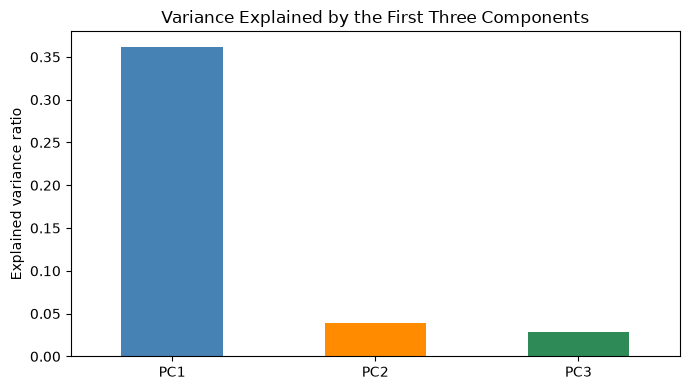

In [9]:
plt.figure(figsize=(7, 4))
explained.plot.bar(color=["steelblue", "darkorange", "seagreen"])
plt.title("Variance Explained by the First Three Components")
plt.ylabel("Explained variance ratio")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Stock weights inside each component

These coefficients are **PCA loadings**, not long-only portfolio allocations. Their squared values sum to one within each component, and negative weights are allowed. A large absolute loading means that the stock contributes strongly to that component.

For every component, the first panel below includes all 502 stocks sorted by loading. The second panel identifies the fifteen most negative and fifteen most positive loadings.


In [10]:
def plot_component_loadings(loadings, component, n_each_side=15):
    values = loadings[component].sort_values()
    extremes = pd.concat([
        values.head(n_each_side),
        values.tail(n_each_side),
    ]).sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    colors_all = np.where(values >= 0, "steelblue", "firebrick")
    axes[0].bar(np.arange(len(values)), values.values, color=colors_all, width=1.0)
    axes[0].axhline(0, color="black", linewidth=0.8)
    axes[0].set_title(f"{component}: All {len(values)} Stock Loadings")
    axes[0].set_xlabel("Stocks sorted from lowest to highest loading")
    axes[0].set_ylabel("PCA loading")
    axes[0].set_xticks([])

    colors_extreme = ["steelblue" if value >= 0 else "firebrick" for value in extremes]
    axes[1].barh(extremes.index, extremes.values, color=colors_extreme)
    axes[1].axvline(0, color="black", linewidth=0.8)
    axes[1].set_title(f"{component}: Largest Positive and Negative Loadings")
    axes[1].set_xlabel("PCA loading")

    plt.tight_layout()
    plt.show()


def scrollable_loading_table(series, height=420):
    table = series.rename("Loading").sort_values(ascending=False).to_frame()
    html = table.to_html(float_format=lambda value: f"{value:.6f}")
    display(HTML(f'<div style="max-height:{height}px; overflow-y:auto;">{html}</div>'))


### Principal component 1: every stock weight

The complete PC1 table is shown in a scrollable block, followed by a plot of all stock loadings and an annotated plot of the largest positive and negative weights.


,Loading
Ticker,
HON,0.064480
DOV,0.063448
AMP,0.063058
IVZ,0.062889
PH,0.062627
ITW,0.062353
IEX,0.062349
TROW,0.061802
PPG,0.061694


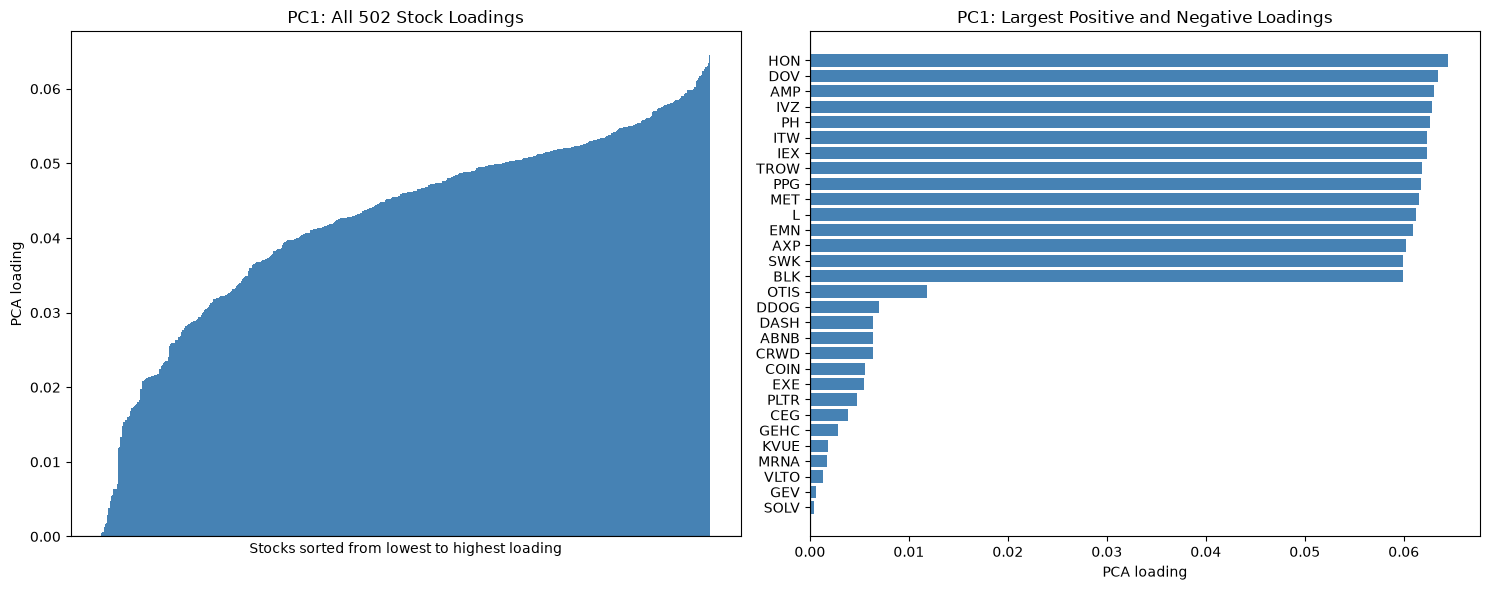

In [11]:
scrollable_loading_table(component_loadings["PC1"])
plot_component_loadings(component_loadings, "PC1")


### Principal component 2: stock weights


,PC2 loading
Ticker,
ED,0.163899
WEC,0.159517
XEL,0.154465
DUK,0.152430
SO,0.152250
AEP,0.148627
D,0.144821
CMS,0.144751
ES,0.143249


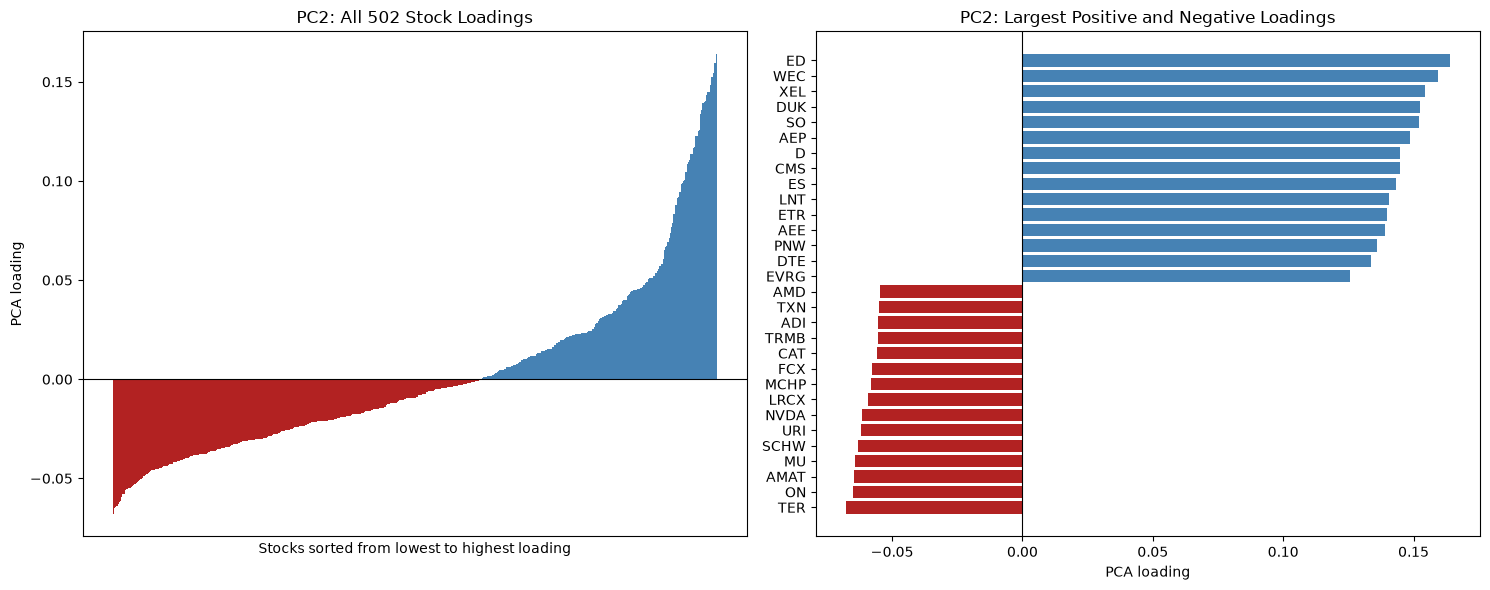

In [12]:
display(
    component_loadings["PC2"]
    .sort_values(key=np.abs, ascending=False)
    .head(30)
    .rename("PC2 loading")
    .to_frame()
    .style.format("{:.6f}")
)
plot_component_loadings(component_loadings, "PC2")


### Principal component 3: stock weights


,PC3 loading
Ticker,
SNPS,0.113609
HBAN,-0.106970
WFC,-0.105863
MTB,-0.102355
ADBE,0.100323
MSFT,0.098711
TYL,0.096869
RF,-0.096256
APA,-0.095802


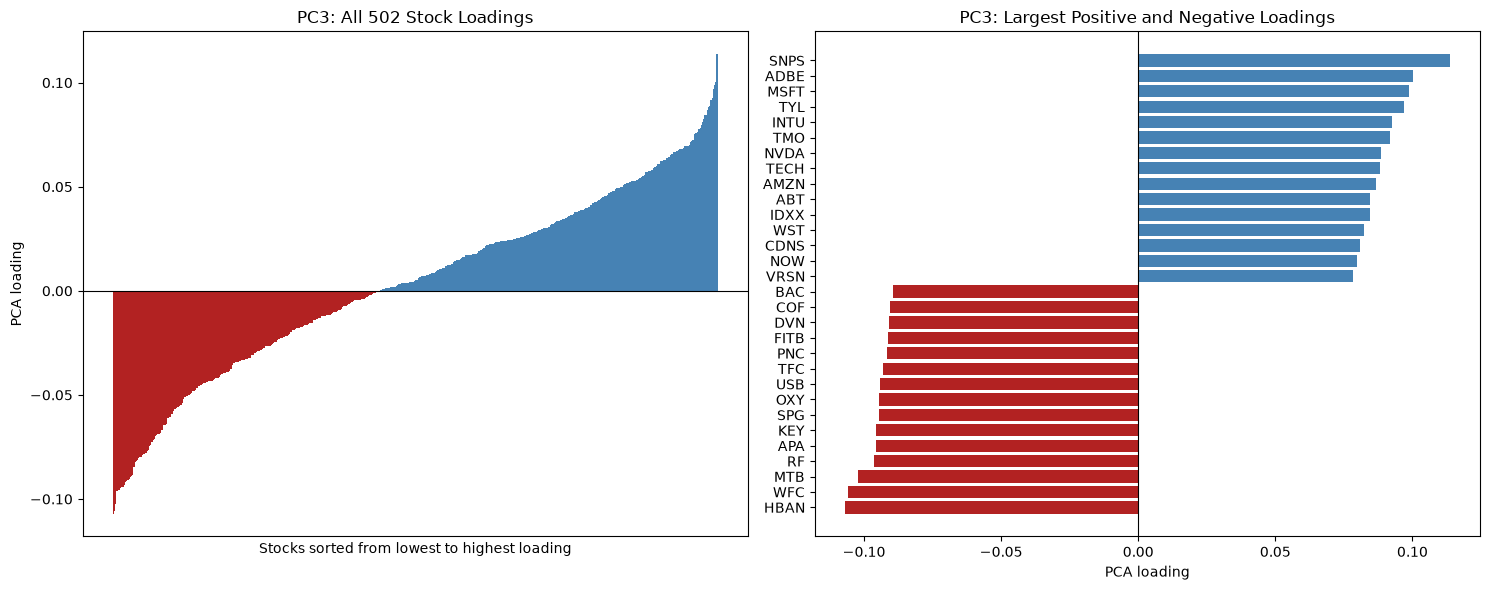

In [13]:
display(
    component_loadings["PC3"]
    .sort_values(key=np.abs, ascending=False)
    .head(30)
    .rename("PC3 loading")
    .to_frame()
    .style.format("{:.6f}")
)
plot_component_loadings(component_loadings, "PC3")


## Component scores through time

Each subplot shows one weekly PCA score series. Keeping them in separate blocks makes differences in scale and behavior easier to see.


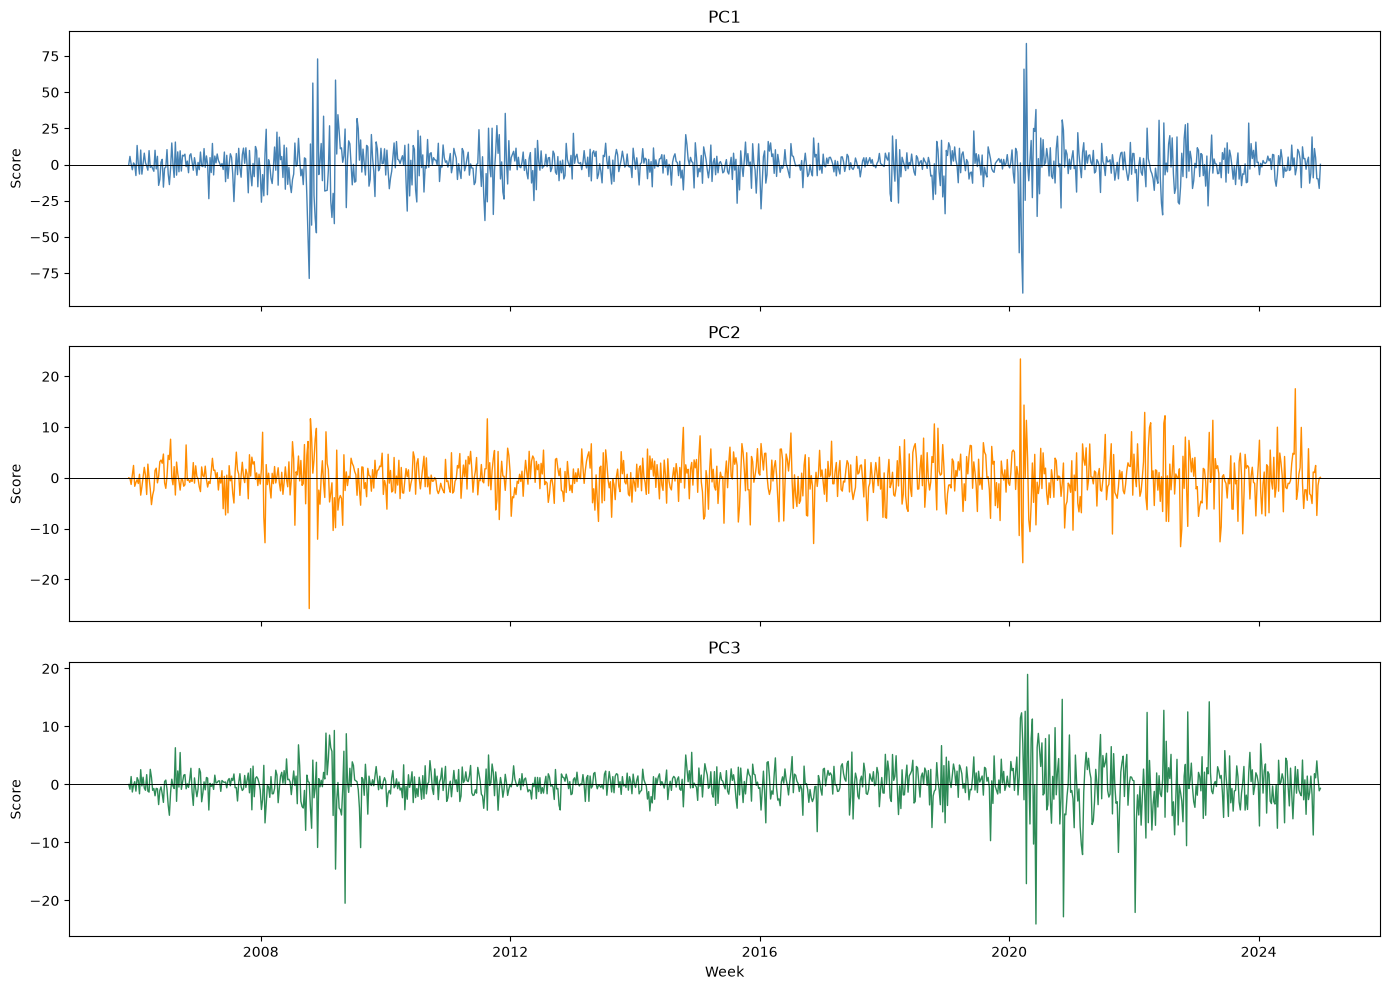

In [14]:
score_dates = component_scores.index.to_timestamp(how="end")
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
colors = ["steelblue", "darkorange", "seagreen"]

for component, color, axis in zip(component_scores.columns, colors, axes):
    axis.plot(score_dates, component_scores[component], color=color, linewidth=1)
    axis.axhline(0, color="black", linewidth=0.7)
    axis.set_title(component)
    axis.set_ylabel("Score")

axes[-1].set_xlabel("Week")
plt.tight_layout()
plt.show()


## Correlation with market, size, and value

The PCA scores are joined to the weekly Fama-French factors over the same weeks. Remember that a PCA vector can be multiplied by minus one without changing the component, so correlation magnitude is more important than sign.


In [15]:
comparison = component_scores.join(factors, how="inner")
factor_correlation = comparison.corr().loc[
    ["PC1", "PC2", "PC3"],
    ["Mkt-RF", "SMB", "HML"],
]

display(factor_correlation.style.format("{:.3f}"))


,Mkt-RF,SMB,HML
PC1,0.969,0.267,0.317
PC2,-0.071,-0.339,-0.067
PC3,0.117,0.069,-0.790


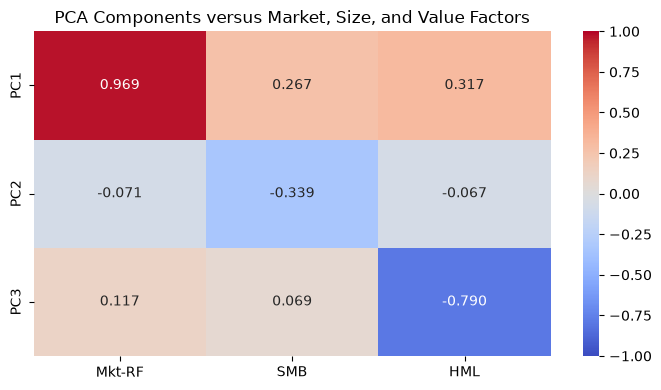

In [16]:
plt.figure(figsize=(7, 4))
sns.heatmap(
    factor_correlation,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("PCA Components versus Market, Size, and Value Factors")
plt.tight_layout()
plt.show()


### Component-factor relationships, one block at a time

The fitted line is included only to make the direction and strength of each relationship visually clear.


In [17]:
def plot_component_factor(component, factor, color):
    correlation = comparison[[component, factor]].corr().iloc[0, 1]
    plt.figure(figsize=(7, 5))
    sns.regplot(
        data=comparison,
        x=factor,
        y=component,
        scatter_kws={"alpha": 0.35, "s": 22},
        line_kws={"color": "black"},
        color=color,
    )
    plt.title(f"{component} versus {factor} (correlation = {correlation:.3f})")
    plt.tight_layout()
    plt.show()


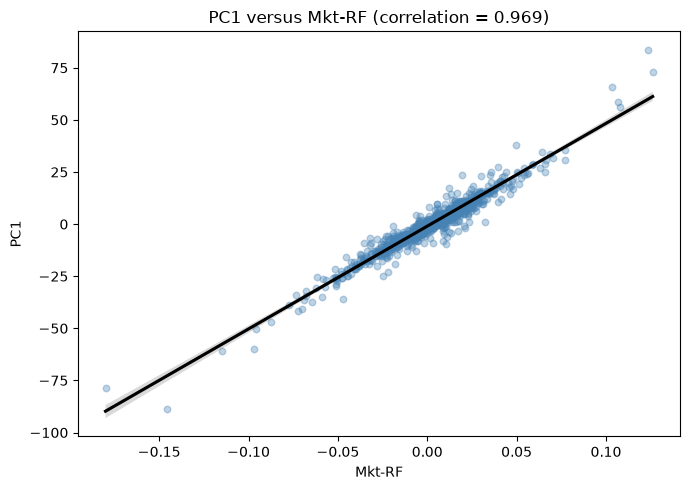

In [18]:
plot_component_factor("PC1", "Mkt-RF", "steelblue")


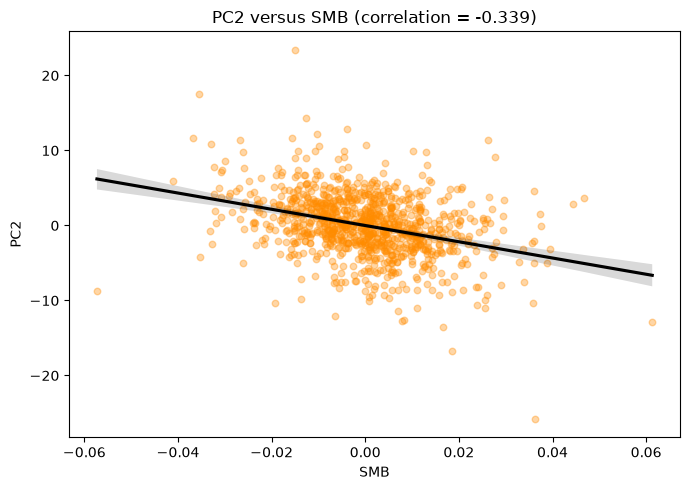

In [19]:
plot_component_factor("PC2", "SMB", "darkorange")


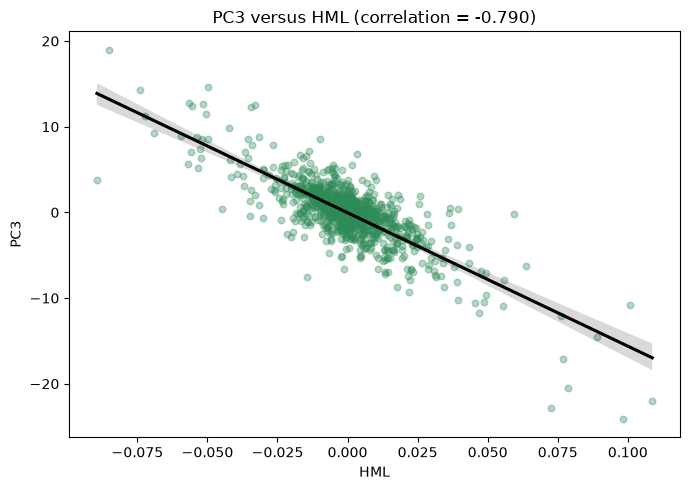

In [20]:
plot_component_factor("PC3", "HML", "seagreen")
